# Etap 1 — Temat projektu, cel analizy, źródła i zbiory danych

**Autorzy:** Adrian Tusiński, Aleksander Klank

**Przedmiot:** Metody analizy, przetwarzania i wizualizacji danych
**Temat:** Analiza dostępności cenowej mieszkań w największych miastach Polski w relacji do lokalnych wynagrodzeń i kosztów życia.

**Rezultat etapu (wg wytycznych):** wybór tematu, określenie celu analizy, pozyskanie minimum dwóch zbiorów danych oraz określenie ich źródeł.

## 1.1 Cel analizy i uzasadnienie

**Główny cel:** ocena *realnej* dostępności mieszkaniowej w Polsce przez wyznaczenie wskaźników dochodowych
(relacja ceny m² do pensji, liczba lat oszczędzania na wkład własny) oraz porównanie opłacalności zakupu i najmu w poszczególnych miastach.

Sama cena za m² nie mówi nic o sytuacji mieszkańców bez kontekstu lokalnych zarobków i kosztów utrzymania —
dlatego łączymy dane ofertowe z danymi o wynagrodzeniach i kosztach życia.

**Zastosowanie praktyczne:**
- **kupujący / migrujący** — wybór miasta na podstawie realnej siły nabywczej,
- **inwestorzy** — porównanie rentowności najmu (stopa zwrotu brutto) między miastami,
- **analitycy rynku** — wskazanie miast o największej presji cenowej względem dochodów.

## 1.2 Pytania analityczne

1. **Dostępność dochodowa** — ile miesięcznych pensji netto (lub lat oszczędzania przy stopie 30%) potrzeba na zakup mieszkania 50 m²?
2. **Zakup vs najem** — gdzie stosunek rocznego czynszu do ceny zakupu jest najkorzystniejszy dla inwestora, a gdzie bardziej opłaca się wynajmować?
3. **Czynniki mikrolokalizacyjne** — jak odległość od centrum, rok budowy i infrastruktura w promieniu 500 m wpływają na cenę m²?
4. **Dochód dyspozycyjny** — jak wydłuża się czas oszczędzania na wkład własny (20%), gdy od pensji odejmiemy podstawowe koszty życia?
5. **Zróżnicowanie regionalne** — czy miasta o najwyższych zarobkach (Warszawa, Kraków) są względnie bardziej czy mniej dostępne niż ośrodki regionalne?

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))
from src.utils import *  # ścieżki, wczytywanie danych, styl wykresów

set_plot_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 1.3 Źródła danych

| # | Zbiór | Źródło | Format | Pliki |
|---|-------|--------|--------|-------|
| 1 | **Apartment Prices in Poland** | Kaggle (oferty z polskich serwisów ogłoszeniowych, 2023–2024, wzbogacone o dane OpenStreetMap) | CSV | `apartments_pl_YYYY_MM.csv` (sprzedaż), `apartments_rent_pl_YYYY_MM.csv` (najem) |
| 2 | **Poland cost of living vs salary per city** | Kaggle (dane zagregowane z GUS/BDL oraz wskaźników kosztów życia typu Numbeo) | CSV | `poland_cost_of_living_vs_salary_2024.csv` (przekrój 2024), `poland_col_salary_longitudinal_2010_2024.csv` (szereg czasowy) |

Pliki zostały pobrane z Kaggle i umieszczone w katalogu `data/raw/` bez modyfikacji (dane surowe).

In [2]:
raw_files = sorted(RAW_DIR.rglob("*.csv"))
files_df = pd.DataFrame({
    "katalog": [p.parent.name for p in raw_files],
    "plik": [p.name for p in raw_files],
    "rozmiar_MB": [round(p.stat().st_size / 1024**2, 2) for p in raw_files],
})
print(f"Liczba plików: {len(files_df)}, łączny rozmiar: {files_df['rozmiar_MB'].sum():.1f} MB")
files_df

Liczba plików: 21, łączny rozmiar: 48.2 MB


,katalog,plik,rozmiar_MB
0,apartments_prices,apartments_pl_2023_08.csv,3.39
1,apartments_prices,apartments_pl_2023_09.csv,3.05
2,apartments_prices,apartments_pl_2023_10.csv,2.99
3,apartments_prices,apartments_pl_2023_11.csv,2.93
4,apartments_prices,apartments_pl_2023_12.csv,2.96
5,apartments_prices,apartments_pl_2024_01.csv,2.79
6,apartments_prices,apartments_pl_2024_02.csv,2.94
7,apartments_prices,apartments_pl_2024_03.csv,3.12
8,apartments_prices,apartments_pl_2024_04.csv,3.47
9,apartments_prices,apartments_pl_2024_05.csv,3.65


## 1.4 Wczytanie zbiorów

Pliki miesięczne łączymy w jeden DataFrame osobno dla **sprzedaży** i **najmu** (kolumna `price` ma w nich inne znaczenie:
cena całkowita vs miesięczny czynsz). Do każdego wiersza dopisujemy okres (`period`) odczytany z nazwy pliku — to nasz wymiar czasowy.

In [3]:
sales_raw = load_apartments("sale")
rent_raw = load_apartments("rent")
cost_2024 = load_cost_2024()
cost_long = load_cost_longitudinal()

summary = pd.DataFrame({
    "zbiór": ["Oferty sprzedaży", "Oferty najmu", "Koszty życia 2024", "Koszty życia 2010–2024"],
    "wiersze": [len(sales_raw), len(rent_raw), len(cost_2024), len(cost_long)],
    "kolumny": [sales_raw.shape[1], rent_raw.shape[1], cost_2024.shape[1], cost_long.shape[1]],
    "poziom szczegółowości": ["oferta × miesiąc", "oferta × miesiąc", "miasto", "miasto × rok"],
})
summary

,zbiór,wiersze,kolumny,poziom szczegółowości
0,Oferty sprzedaży,195568,30,oferta × miesiąc
1,Oferty najmu,70847,30,oferta × miesiąc
2,Koszty życia 2024,295,19,miasto
3,Koszty życia 2010–2024,2745,22,miasto × rok


In [4]:
sales_raw.head()

,id,city,type,squareMeters,rooms,floor,floorCount,buildYear,latitude,longitude,centreDistance,poiCount,schoolDistance,clinicDistance,postOfficeDistance,kindergartenDistance,restaurantDistance,collegeDistance,pharmacyDistance,ownership,buildingMaterial,condition,hasParkingSpace,hasBalcony,hasElevator,hasSecurity,hasStorageRoom,price,source_file,period
0,f8524536d4b09a0c8ccc0197ec9d7bde,szczecin,blockOfFlats,63.00,3.00,4.00,10.00,"1,980.00",53.38,14.63,6.53,9.00,0.12,1.39,0.63,0.10,1.65,NaN,0.41,condominium,concreteSlab,NaN,yes,yes,yes,no,yes,415000,apartments_pl_2023_08.csv,2023-08
1,accbe77d4b360fea9735f138a50608dd,szczecin,blockOfFlats,36.00,2.00,8.00,10.00,NaN,53.44,14.56,2.15,16.00,0.27,0.49,0.65,0.29,0.35,1.40,0.20,cooperative,concreteSlab,NaN,no,yes,yes,no,yes,395995,apartments_pl_2023_08.csv,2023-08
2,8373aa373dbc3fe7ca3b7434166b8766,szczecin,tenement,73.02,3.00,2.00,3.00,NaN,53.45,14.55,3.24,9.00,0.28,0.67,0.37,0.25,0.30,1.86,0.28,condominium,brick,NaN,no,no,no,no,no,565000,apartments_pl_2023_08.csv,2023-08
3,0a68cd14c44ec5140143ece75d739535,szczecin,tenement,87.60,3.00,2.00,3.00,NaN,53.44,14.53,2.27,32.00,0.17,0.26,0.22,0.36,0.10,0.31,0.09,condominium,brick,NaN,yes,yes,no,no,yes,640000,apartments_pl_2023_08.csv,2023-08
4,f66320e153c2441edc0fe293b54c8aeb,szczecin,blockOfFlats,66.00,3.00,1.00,3.00,NaN,53.41,14.50,4.07,1.00,0.22,1.69,0.50,0.70,0.50,2.14,0.51,condominium,NaN,NaN,no,no,no,no,no,759000,apartments_pl_2023_08.csv,2023-08


In [5]:
cost_2024.head()

,city,voivodeship,powiat_type,city_tier,population_approx,avg_salary_gross_pln,median_salary_gross_pln,median_salary_net_pln,cost_of_living_index,rent_1br_city_center_pln,rent_1br_outside_center_pln,meal_cheap_restaurant_pln,groceries_monthly_pln,public_transport_monthly_pln,est_monthly_cost_single_pln,affordability_ratio,rent_to_income_pct,data_source,data_year
0,Warszawa,Mazowieckie,miasto na prawach powiatu,metropolis,1800000,10800,8208,5893,98.50,3864,2640,44,1361,154,5335,1.10,24.40,numbeo,2024
1,Kraków,Małopolskie,miasto na prawach powiatu,metropolis,800000,10200,7752,5566,92.00,3668,2716,43,1439,157,5472,1.02,26.60,numbeo,2024
2,Łódź,Łódzkie,miasto na prawach powiatu,metropolis,685000,8100,6156,4420,76.00,3654,2637,45,1368,159,5364,0.82,32.60,numbeo,2024
3,Wrocław,Dolnośląskie,miasto na prawach powiatu,metropolis,650000,10400,7904,5675,90.00,3945,2884,46,1361,145,5610,1.01,27.70,numbeo,2024
4,Poznań,Wielkopolskie,miasto na prawach powiatu,metropolis,540000,9800,7448,5348,87.00,3581,2683,43,1424,151,5418,0.99,27.40,numbeo,2024


In [6]:
cost_long.head()

,year,city,voivodeship,city_tier,population_approx,avg_salary_gross_pln,median_salary_gross_pln,median_salary_net_pln,national_avg_salary_gross_pln,national_min_wage_pln,salary_to_national_ratio,cpi_annual_pct,cost_of_living_index,rent_1br_city_center_pln,rent_1br_outside_center_pln,meal_cheap_restaurant_pln,groceries_monthly_pln,public_transport_monthly_pln,est_monthly_cost_single_pln,affordability_ratio,rent_to_income_pct,data_source
0,2010,Warszawa,Mazowieckie,metropolis,1800000,4145,3171,2277,3224,1317,1.29,2.60,93.10,2238,1661,28,835,90,3329,0.68,40.10,numbeo
1,2011,Warszawa,Mazowieckie,metropolis,1800000,4447,3402,2443,3399,1386,1.31,4.30,94.00,2518,1775,28,897,93,3515,0.70,39.90,numbeo
2,2012,Warszawa,Mazowieckie,metropolis,1800000,4666,3569,2563,3521,1500,1.32,3.70,94.10,2473,1877,29,933,101,3688,0.69,40.20,numbeo
3,2013,Warszawa,Mazowieckie,metropolis,1800000,4641,3550,2549,3650,1600,1.27,0.90,95.30,2531,1911,30,923,98,3731,0.68,41.20,numbeo
4,2014,Warszawa,Mazowieckie,metropolis,1800000,4687,3586,2575,3783,1680,1.24,0.00,94.50,2647,1866,30,960,100,3725,0.69,39.80,numbeo


## 1.5 Zakres czasowy i przestrzenny

Liczba ofert w kolejnych miesiącach (dane czasowe) oraz liczba ofert w miastach (dane przestrzenne).

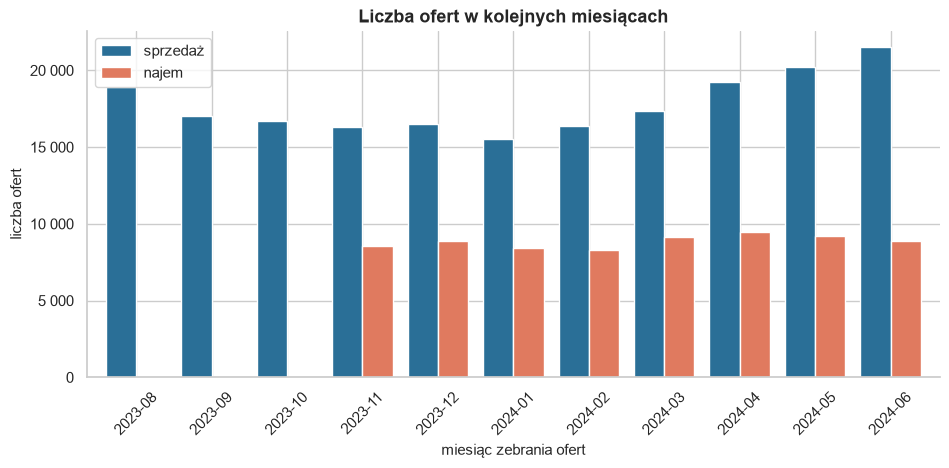

period,2023-08,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06
sprzedaż,18905,16997,16690,16302,16483,15521,16361,17318,19259,20231,21501
najem,0,0,0,8533,8872,8430,8318,9152,9484,9209,8849


In [7]:
coverage = pd.concat({
    "sprzedaż": sales_raw.groupby("period").size(),
    "najem": rent_raw.groupby("period").size(),
}, axis=1).fillna(0).astype(int)
coverage.index = coverage.index.astype(str)

fig, ax = plt.subplots(figsize=(11, 4.5))
coverage.plot(kind="bar", ax=ax, width=0.8, color=["#2a6f97", "#e07a5f"])
ax.set_title("Liczba ofert w kolejnych miesiącach")
ax.set_xlabel("miesiąc zebrania ofert")
ax.set_ylabel("liczba ofert")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
ax.tick_params(axis="x", rotation=45)
save_fig(fig, "01_oferty_w_czasie")
plt.show()
coverage.T

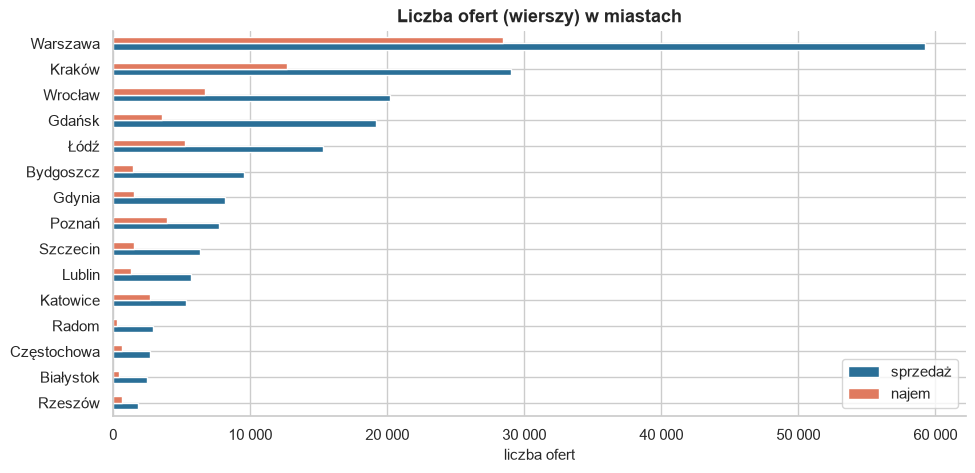

In [8]:
city_counts = pd.concat({
    "sprzedaż": sales_raw["city"].value_counts(),
    "najem": rent_raw["city"].value_counts(),
}, axis=1)
city_counts.index = [city_label(c) for c in city_counts.index]

fig, ax = plt.subplots(figsize=(11, 5))
city_counts.sort_values("sprzedaż").plot(kind="barh", ax=ax, color=["#2a6f97", "#e07a5f"])
ax.set_title("Liczba ofert (wierszy) w miastach")
ax.set_xlabel("liczba ofert")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(thousands))
save_fig(fig, "01_oferty_w_miastach")
plt.show()

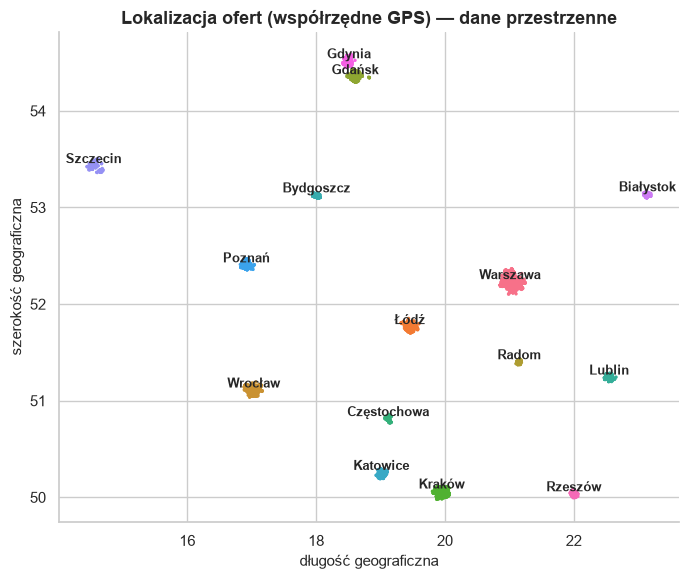

In [9]:
sample = sales_raw.sample(20000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(8, 8))
sns.scatterplot(data=sample, x="longitude", y="latitude", hue="city", s=6, linewidth=0, ax=ax, legend=False)
for city, grp in sample.groupby("city"):
    ax.annotate(city_label(city), (grp["longitude"].median(), grp["latitude"].median()),
                fontsize=9, fontweight="bold", ha="center", va="bottom")
ax.set_title("Lokalizacja ofert (współrzędne GPS) — dane przestrzenne")
ax.set_xlabel("długość geograficzna")
ax.set_ylabel("szerokość geograficzna")
ax.set_aspect(1.5)
save_fig(fig, "01_mapa_ofert")
plt.show()

## 1.6 Rodzaje danych

| Rodzaj | Gdzie występuje w projekcie | Zastosowanie |
|--------|-----------------------------|--------------|
| **Strukturalne (tabularne)** | wszystkie pliki CSV — stałe kolumny i typy | statystyka opisowa, wskaźniki, regresja, grupowanie |
| **Półstrukturalne** | brak w surowych danych; w projekcie powstają np. metadane notebooków (JSON) i workflow KNIME (XML) | — |
| **Niestrukturalne** | brak (np. opisy ogłoszeń, zdjęcia nie są częścią zbioru) | — |
| **Czasowe** | `period` (miesiąc zebrania ofert 2023-08 → 2024-06), `year` w szeregu 2010–2024 | dynamika cen i płac |
| **Przestrzenne** | `latitude`, `longitude`, `centreDistance`, odległości do POI, `city` | agregacja per miasto, wpływ lokalizacji, mapy |

## 1.7 Wspólne atrybuty — klucz integracji

Zbiory łączymy po **nazwie miasta**. W danych ofertowych nazwy są zapisane małymi literami bez polskich znaków (`krakow`),
a w danych o kosztach życia — poprawną polszczyzną (`Kraków`). Konieczna jest więc standaryzacja (funkcja `normalize_city`).

In [10]:
apartment_cities = set(sales_raw["city"].unique())
cost_cities = set(cost_2024["city"].map(normalize_city))
print("Miasta w danych ofertowych:", len(apartment_cities))
print("Miasta w danych o kosztach życia:", len(cost_cities))
print("Miasta wspólne po standaryzacji:", len(apartment_cities & cost_cities))
print("Brak dopasowania:", apartment_cities - cost_cities or "—")

Miasta w danych ofertowych: 15
Miasta w danych o kosztach życia: 290
Miasta wspólne po standaryzacji: 15
Brak dopasowania: —


## 1.8 Prywatność, bezpieczeństwo i legalność danych

- Zbiory są **publiczne** (Kaggle) i udostępnione do celów analitycznych/edukacyjnych — korzystamy z nich zgodnie z licencją.
- **Brak danych osobowych** (RODO): oferty nie zawierają nazwisk, telefonów ani adresów; `id` to skrót (hash) — nie identyfikuje osoby.
- Współrzędne GPS dotyczą ofert (budynków), a nie osób; w wizualizacjach pokazujemy dane zagregowane.
- Dane o wynagrodzeniach są **zagregowane per miasto** (średnie/mediany) — nie da się z nich odtworzyć informacji o jednostce.
- Surowe pliki przechowujemy bez zmian w `data/raw/`, a wszystkie przekształcenia są powtarzalne (kod w notebookach) — zachowujemy pochodzenie danych (*data lineage*).

## 1.9 Podsumowanie etapu

- Temat: dostępność mieszkań w 15 największych miastach Polski vs zarobki i koszty życia.
- Pozyskano **2 zbiory danych** (łącznie 21 plików CSV) z dwóch różnych źródeł: oferty nieruchomości i statystyki płac/kosztów życia.
- Dane zawierają wymiar **tabularny, czasowy i przestrzenny**; klucz integracji to znormalizowana nazwa miasta — wszystkie 15 miast ofertowych ma odpowiednik w danych o kosztach życia.